1. Libraries

In [ ]:

# YOLO11 instance segmentation
!pip install -q ultralytics pycocotools opencv-python-headless pyyaml

import os
import json
import random
import shutil
import zipfile
from pathlib import Path

import cv2
import yaml
import numpy as np
import torch

from google.colab import files
from ultralytics import YOLO

print("PyTorch:", torch.__version__)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cu130


3. ZIP extract

In [ ]:
import zipfile
from pathlib import Path
import gdown

# 1. Paste your Google Drive share link here
drive_url = "https://drive.google.com/file/d/1dweEilL3ZYaafvzYmJ2gkQ3zmWutZrCI/view?usp=sharing"
zip_name = "concrete.v8i.coco"

# 2. Download the ZIP file from Drive
gdown.download(url=drive_url, output=zip_name, quiet=False, fuzzy=True)

# 3. Extract the ZIP file
EXTRACT_DIR = Path("/content/coco_dataset")
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("ZIP extracted successfully!")
print("Dataset location:", EXTRACT_DIR)

# 4. Check extracted files/folders
for path in list(EXTRACT_DIR.rglob("*"))[:40]:
    print(path.relative_to(EXTRACT_DIR))


Downloading...
From (original): https://drive.google.com/uc?id=1dweEilL3ZYaafvzYmJ2gkQ3zmWutZrCI
From (redirected): https://drive.google.com/uc?id=1dweEilL3ZYaafvzYmJ2gkQ3zmWutZrCI&confirm=t&uuid=180f466e-6575-45d5-960c-c900ce7c4c8b
To: /content/concrete.v8i.coco
100%|██████████| 380M/380M [00:05<00:00, 72.5MB/s]


ZIP extracted successfully!
Dataset location: /content/coco_dataset
train
valid
README.dataset.txt
README.roboflow.txt
test
train/7079-81_jpg.rf.055c62644e199f90f255037dde41caea.jpg
train/7127-183_jpg.rf.bfc77c28a3bca655187b235a8ca1396f.jpg
train/56212_20190410165231913060_0_jpg.rf.2d5ff61f411acfa956c9cd7d56433be9.jpg
train/2025-07-15-11-10-52_1_jpg.rf.41419fa58fdfb62d3e09f0ee0bbba027.jpg
train/IMG_20240726_104846_1_jpg.rf.11346117e23c6b4ab128a8594d2fe943.jpg
train/7069-177_jpg.rf.106904ea07b3c8efb65407fe583d98d4.jpg
train/747_jpg.rf.da7f6218e841b09d0134a0f62faad96e.jpg
train/IMG_20240726_105538_jpg.rf.62bf3306e8aa79ad2a65a2a6d1a9199a.jpg
train/7124-113_jpg.rf.8b0772ca98f36f97f85ce0a8e9039fc7.jpg
train/IMG_20240726_110444_jpg.rf.f9afbdc20e0bbe9373818e9a3621441f.jpg
train/IMG_20240726_105538_jpg.rf.8e0b69eceb0d4d5495bf695e11c3d077.jpg
train/7093-207_jpg.rf.e3902944967daea82f71fee427219b7c.jpg
train/1846e35f97dead57fad07d4f89039626_jpeg.rf.edae8bb5f678d92582788728d1ed4fc4.jpg
train/7131-

4. COCO JSON file locate

In [ ]:

json_files = list(EXTRACT_DIR.rglob("*.json"))

print("JSON files found:")
for i, path in enumerate(json_files):
    print(i, path)

if not json_files:
    raise FileNotFoundError("Dataset ZIP ke andar koi JSON file nahi mili.")
JSON_PATH = json_files[0]

with open(JSON_PATH, "r", encoding="utf-8") as f:
    coco_data = json.load(f)

print("\nSelected JSON:", JSON_PATH)
print("Images:", len(coco_data.get("images", [])))
print("Annotations:", len(coco_data.get("annotations", [])))
print("Categories:", coco_data.get("categories", []))


JSON files found:
0 /content/coco_dataset/train/_annotations.coco.json
1 /content/coco_dataset/valid/_annotations.coco.json
2 /content/coco_dataset/test/_annotations.coco.json

Selected JSON: /content/coco_dataset/train/_annotations.coco.json
Images: 2568
Annotations: 4815
Categories: [{'id': 0, 'name': 'concrete', 'supercategory': 'none'}, {'id': 1, 'name': 'crack', 'supercategory': 'concrete'}, {'id': 2, 'name': 'hole', 'supercategory': 'concrete'}, {'id': 3, 'name': 'honeycombe', 'supercategory': 'concrete'}, {'id': 4, 'name': 'pitting', 'supercategory': 'concrete'}, {'id': 5, 'name': 'spalling', 'supercategory': 'concrete'}]


5. Dataset images locate and categories mapping

In [ ]:

image_lookup = {}

for img_path in EXTRACT_DIR.rglob("*"):
    if img_path.is_file():
        image_lookup.setdefault(img_path.name, img_path)
categories = sorted(coco_data["categories"], key=lambda x: x["id"])

category_mapping = {
    category["id"]: index
    for index, category in enumerate(categories)
}

class_names = [category["name"] for category in categories]

print("Class mapping:")
for category in categories:
    print(category["id"], "->", category_mapping[category["id"]],
          ":", category["name"])

print("\nTotal classes:", len(class_names))


Class mapping:
0 -> 0 : concrete
1 -> 1 : crack
2 -> 2 : hole
3 -> 3 : honeycombe
4 -> 4 : pitting
5 -> 5 : spalling

Total classes: 6


6. COCO annotations

In [ ]:
from pycocotools import mask as coco_mask

YOLO_DIR = Path("/content/yolo_dataset")

for split in ["train", "val", "test"]:
    (YOLO_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

annotations_by_image = {}

for ann in coco_data["annotations"]:
    annotations_by_image.setdefault(ann["image_id"], []).append(ann)

image_records = coco_data["images"].copy()
random.seed(42)
random.shuffle(image_records)

total = len(image_records)
train_end = int(total * 0.80)
val_end = int(total * 0.90)

splits = {
    "train": image_records[:train_end],
    "val": image_records[train_end:val_end],
    "test": image_records[val_end:]
}

def get_polygon(segmentation, image_height, image_width):
    """
    COCO segmentation ko polygon points mein convert karta hai.
    Returns: normalized polygon coordinates.
    """

    polygons = []

    # Case 1: COCO polygon format
    if isinstance(segmentation, list):
        for polygon in segmentation:
            if len(polygon) >= 6 and len(polygon) % 2 == 0:
                polygons.append(polygon)

        if not polygons:
            return None

        polygon = max(polygons, key=len)

    # Case 2: COCO RLE format
    elif isinstance(segmentation, dict):
        try:
            rle = segmentation

            if isinstance(rle.get("counts"), list):
                rle = coco_mask.frPyObjects(
                    rle, image_height, image_width
                )

            mask = coco_mask.decode(rle)

            if mask.ndim == 3:
                mask = np.any(mask, axis=2).astype(np.uint8)

            mask = mask.astype(np.uint8)

            contours, _ = cv2.findContours(
                mask,
                cv2.RETR_EXTERNAL,
                cv2.CHAIN_APPROX_SIMPLE
            )

            if not contours:
                return None

            contour = max(contours, key=cv2.contourArea)

            if len(contour) < 3:
                return None

            polygon = contour.reshape(-1, 2).flatten().tolist()

        except Exception as e:
            print("RLE conversion error:", e)
            return None

    else:
        return None

    normalized = []

    for i in range(0, len(polygon), 2):
        x = min(max(float(polygon[i]) / image_width, 0), 1)
        y = min(max(float(polygon[i + 1]) / image_height, 0), 1)

        normalized.extend([x, y])

    if len(normalized) < 6:
        return None

    return normalized


converted_count = 0
missing_images = 0
skipped_annotations = 0

for split_name, records in splits.items():

    for img_info in records:

        image_id = img_info["id"]
        file_name = Path(img_info["file_name"]).name

        source_image = image_lookup.get(file_name)

        if source_image is None:
            print("Image missing:", img_info["file_name"])
            missing_images += 1
            continue

        image_width = img_info["width"]
        image_height = img_info["height"]

        output_name = f"{image_id}_{file_name}"

        destination_image = YOLO_DIR / "images" / split_name / output_name
        destination_label = (
            YOLO_DIR / "labels" / split_name /
            f"{Path(output_name).stem}.txt"
        )

        shutil.copy2(source_image, destination_image)

        label_lines = []

        for ann in annotations_by_image.get(image_id, []):

            if ann.get("iscrowd", 0) == 1:
                skipped_annotations += 1
                continue

            category_id = ann["category_id"]

            if category_id not in category_mapping:
                skipped_annotations += 1
                continue

            polygon = get_polygon(
                ann.get("segmentation"),
                image_height,
                image_width
            )

            if polygon is None:
                skipped_annotations += 1
                continue

            class_id = category_mapping[category_id]

            coordinates = " ".join(
                f"{value:.6f}" for value in polygon
            )

            label_lines.append(f"{class_id} {coordinates}")

        with open(destination_label, "w", encoding="utf-8") as f:
            f.write("\n".join(label_lines))

        converted_count += 1

print("\nConversion completed!")
print("Images converted:", converted_count)
print("Missing images:", missing_images)
print("Skipped annotations:", skipped_annotations)

for split_name in splits:
    count = len(list((YOLO_DIR / "images" / split_name).glob("*")))
    print(split_name, "images:", count)



Conversion completed!
Images converted: 2568
Missing images: 0
Skipped annotations: 0
train images: 2054
val images: 257
test images: 257


7. data.yaml

In [ ]:

data_yaml = {
    "path": str(YOLO_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(class_names),
    "names": class_names
}

yaml_path = YOLO_DIR / "data.yaml"

with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.dump(data_yaml, f, sort_keys=False)

print(yaml_path.read_text())


path: /content/yolo_dataset
train: images/train
val: images/val
test: images/test
nc: 6
names:
- concrete
- crack
- hole
- honeycombe
- pitting
- spalling



8. Converted annotations visualize

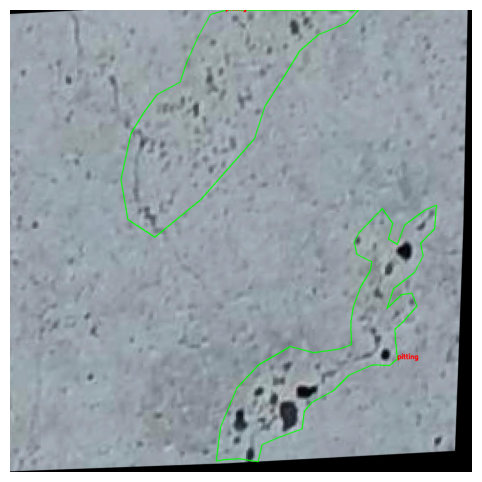

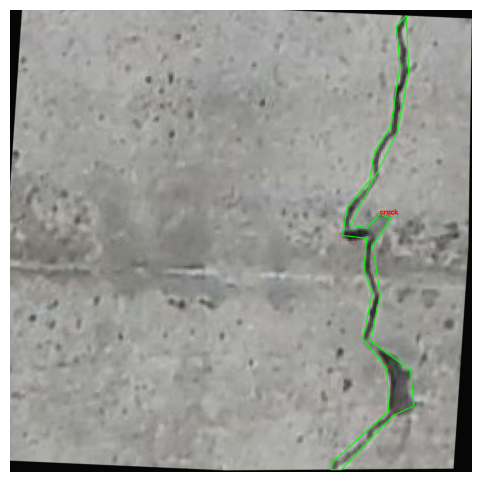

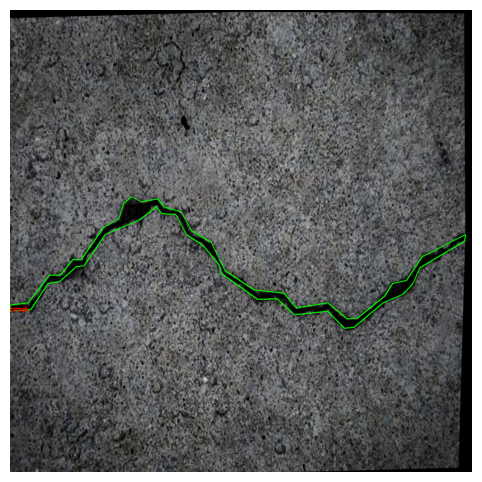

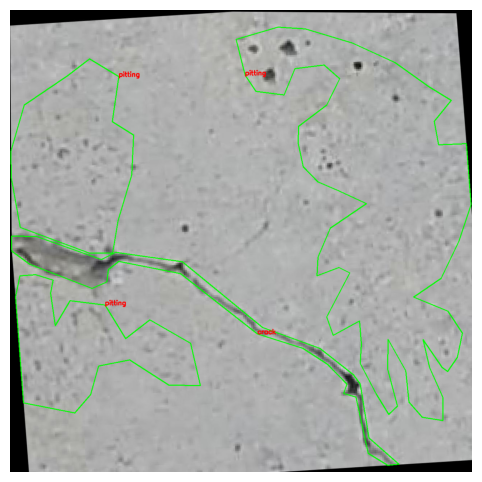

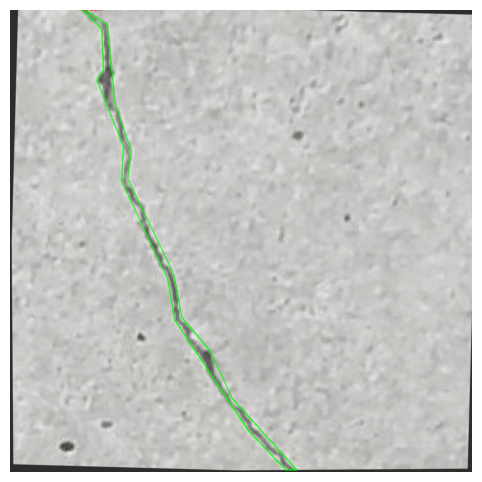

In [ ]:

import matplotlib.pyplot as plt

train_images = list((YOLO_DIR / "images/train").glob("*"))

def show_yolo_annotation(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        print("Image could not be loaded:", image_path)
        return

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w = image.shape[:2]

    label_path = (
        YOLO_DIR / "labels/train" /
        f"{image_path.stem}.txt"
    )

    if label_path.exists():
        with open(label_path, "r") as f:
            lines = f.readlines()

        for line in lines:
            values = list(map(float, line.strip().split()))

            class_id = int(values[0])
            points = np.array(values[1:]).reshape(-1, 2)

            points[:, 0] *= w
            points[:, 1] *= h

            points = points.astype(np.int32)

            cv2.polylines(
                image,
                [points],
                isClosed=True,
                color=(0, 255, 0),
                thickness=2
            )

            x, y = points[0]
            cv2.putText(
                image,
                class_names[class_id],
                (x, y),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 0, 0),
                2
            )

    plt.figure(figsize=(8, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.show()


# First 5 training images visualize
for image_path in train_images[:5]:
    show_yolo_annotation(image_path)


9: Model load aur training

In [ ]:

model = YOLO("yolo11n-seg.pt")

# Training
results = model.train(
    data=str(yaml_path),

    epochs=50,
    imgsz=640,
    batch=8,

    # Training output
    project="/content/runs/segment",
    name="yolo11n_instance_segmentation",

    patience=10,
    workers=2,

    # Reproducibility
    seed=42,

    # Training augmentation
    fliplr=0.5,
    mosaic=1.0,

    plots=True,
    save=True
)

print("Training completed!")


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_instance_segmentation, nbs=64, nms=None, opset

10. Model evaluation

In [ ]:

# Best trained weights load karna
best_model_path = (
    "/content/runs/segment/"
    "yolo11n_instance_segmentation/weights/best.pt"
)

best_model = YOLO(best_model_path)

# Test dataset par evaluation
metrics = best_model.val(
    data=str(yaml_path),
    split="test",
    imgsz=640,
    batch=8,
    device=0 if torch.cuda.is_available() else "cpu"
)

print("\nInstance Segmentation Evaluation Results")

print("Box mAP50:", metrics.box.map50)
print("Box mAP50-95:", metrics.box.map)

print("Mask mAP50:", metrics.seg.map50)
print("Mask mAP50-95:", metrics.seg.map)


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,850,682 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1719.3±518.8 MB/s, size: 96.3 KB)
val: Scanning /content/yolo_dataset/labels/test... 257 images, 13 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 257/257 1.2Kit/s 0.2s
val: New cache created: /content/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 3.8it/s 8.6s
                   all        257        492      0.732      0.757      0.803      0.586       0.68      0.721      0.753      0.403
                 crack        160        233      0.871      0.809      0.869      0.725      0.868      0.811      0.861      0.397
            honeycombe         13         17      0.603          1      0.952      0.738        0.6          1    

11. Apply segmentation on Test images

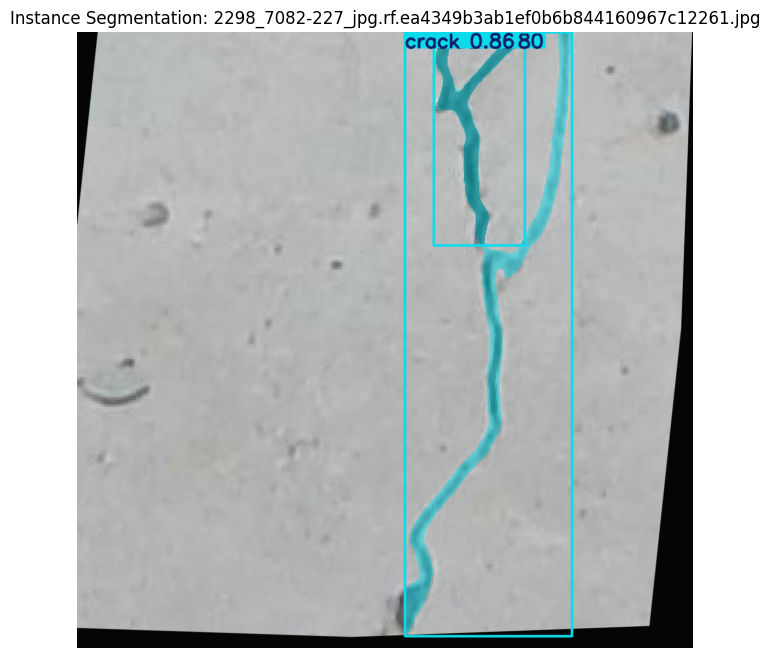

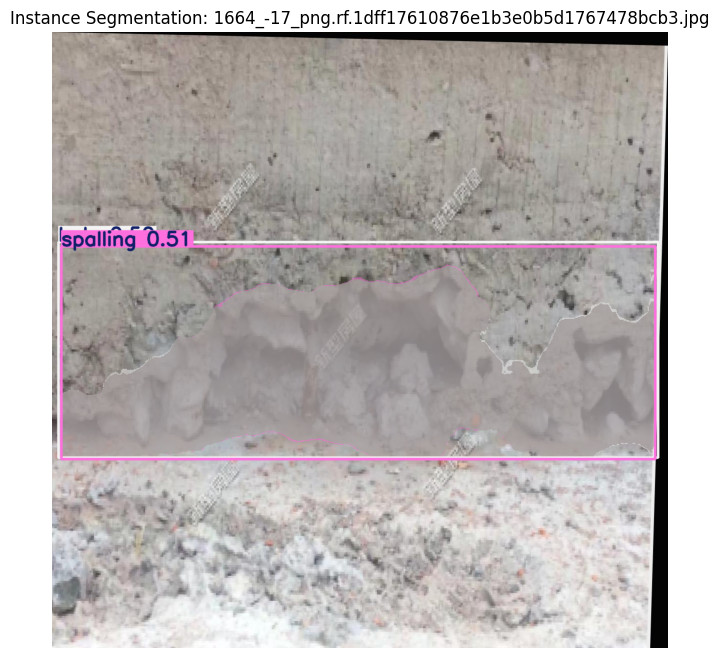

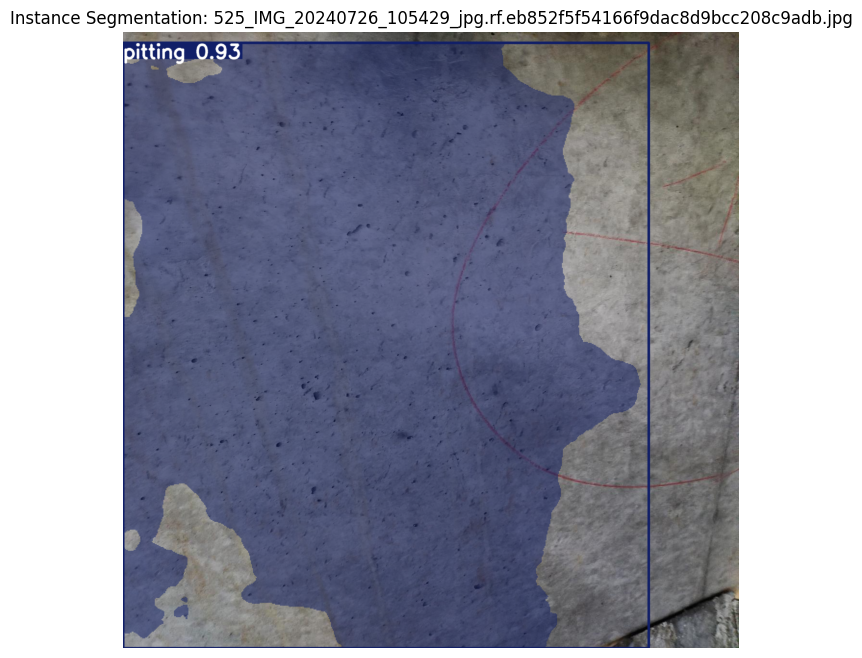

In [ ]:

test_images = list((YOLO_DIR / "images/test").glob("*"))

if len(test_images) < 3:
    raise ValueError("At least 3 test images required.")

for image_path in test_images[:3]:

    result = best_model.predict(
        source=str(image_path),
        conf=0.25,
        verbose=False
    )[0]

    result_image = result.plot()

    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
    plt.title(f"Instance Segmentation: {image_path.name}")
    plt.axis("off")
    plt.show()


12. Multiple test images par prediction

In [ ]:

prediction_results = best_model.predict(
    source=str(YOLO_DIR / "images/test"),
    conf=0.25,
    save=True,
    project="/content/predictions",
    name="test_predictions"
)

print("Predictions saved in /content/predictions/")



image 1/257 /content/yolo_dataset/images/test/1002_IMG_20240726_104710_jpg.rf.f8977a48970c5bdc40aa99d42733db20.jpg: 640x640 3 cracks, 13.7ms
image 2/257 /content/yolo_dataset/images/test/1003_7083-62_jpg.rf.958e9c1e0096d9574e7e0525f3cf4036.jpg: 640x640 1 crack, 1 pitting, 14.0ms
image 3/257 /content/yolo_dataset/images/test/1010_IMG_20240726_104746_jpg.rf.90cced17370168fc4eaa42dadde6cdc9.jpg: 640x640 1 pitting, 13.7ms
image 4/257 /content/yolo_dataset/images/test/1015_7083-169_jpg.rf.8a620243947a94387f7e534ff0f9fead.jpg: 640x640 1 crack, 13.7ms
image 5/257 /content/yolo_dataset/images/test/1018_IMG_6602_JPEG.rf.6295c538b19e29e4886da17cc9aeaf68.jpg: 640x640 1 pitting, 14.6ms
image 6/257 /content/yolo_dataset/images/test/1023_IMG_6597_JPEG.rf.376951592efc844539ba3891135c4712.jpg: 640x640 1 pitting, 13.5ms
image 7/257 /content/yolo_dataset/images/test/1029_2025-07-15-11-10-52_3_jpg.rf.67c68ed014dd351a45cccc27fdf54ce0.jpg: 640x640 5 honeycombes, 13.0ms
image 8/257 /content/yolo_dataset/im

13. Best model download

In [ ]:

from google.colab import files

files.download(best_model_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>